# Modelado Predictivo: Clasificación con Gradient Boosting
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** Este notebook implementa y evalúa un clasificador **Gradient Boosting Multiclase** construido desde cero con ayuda del curso 'Machine_Learning_desde_Cero-11' del Prof. Zucco. 

A diferencia de Random Forest (que entrena árboles profundos e independientes en paralelo mediante *Bagging*), Gradient Boosting construye un ensamble **secuencial y aditivo** de árboles de regresión débiles (`RegressionTree` de poca profundidad). Cada nuevo conjunto de árboles aprende a predecir y corregir los **pseudo-residuos de probabilidad** (el gradiente negativo de la función de pérdida de entropía cruzada multiclase con activación *Softmax*) dejados por las iteraciones anteriores.

### Objetivos del Modelado

1. **Entrenamiento Secuencial Aditivo:** Entrenar un modelo `GradientBoostingClassifier` optimizando la tasa de aprendizaje (`learning_rate`), el número de etapas de boosting (`n_estimators`) y la profundidad de los árboles base (`max_depth`).

2. **Análisis de Evolución por Etapas (`staged_predict`):** Evaluar cómo evoluciona la exactitud y el Macro F1-Score a medida que se agregan árboles al ensamble, verificando la convergencia y descartando sobreajuste (*overfitting*).

3. **Evaluación Clínica Comparativa:** Medir el desempeño por clase mediante la Matriz de Confusión, Recall y F1-Score bajo la misma partición de datos (`seed=42`) utilizada en Random Forest para realizar una comparativa directa y justa.

### Ficha Metodológica del Modelo

* **Descripción breve del método:** Es un ensamble secuencial donde se entrenan árboles de regresión pequeños (`max_depth=3`) uno tras otro a lo largo de n etapas (`n_estimators=100`), de modo que cada nuevo árbol corrige los errores de probabilidad de los anteriores usando una tasa de aprendizaje (`learning_rate=0.1`) y ponderación de clases (`balanced=True`).

* **Justificación de su uso:** Lo elegimos por su capacidad para refinar errores difíciles etapa por etapa en datos tabulares. Al notar que el desbalance original del dataset (77.85% sanos vs. 8.28% patológicos) volvía conservador al algoritmo, implementamos un balanceo de pesos proporcional a la frecuencia de cada clase para obligar a los árboles a priorizar a los bebés en riesgo.

* **Métricas de evaluación utilizadas:** Evaluamos la *Exactitud Global (Accuracy)* y la curva de aprendizaje etapa por etapa con `staged_predict`, además de *Precisión*, *Recall*, *F1-Score* por clase, *Promedio Macro F1-Score* y la *Matriz de Confusión*.

* **Análisis de resultados:** Detallado en la conclusión final, destacando que el balanceo de pesos elevó el **Recall en casos Patológicos a 84.62%** (con **F1-Score de 86.27%**) y en **Sospechosos a 89.23%**, garantizando además una **Precisión del 97.40%** al diagnosticar fetos Normales.

In [1]:
# Importación de librerías 

import os # Gestión de Carpetas
import sys # Config del sistema
import numpy as np # Matemáticas
import pandas as pd # Tablas
import matplotlib.pyplot as plt # Grafico

# Modificación para importar los módulos fuera de la carpeta actual

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importamos el clasificador Gradient Boosting y nuestras utilidades

from src.GradientBoosting import GradientBoostingClassifier
from src.utils_and_metrics import train_test_split, accuracy, confusion_matrix, precision, recall, f1_score

In [2]:
# Carga directa de matrices X & y generadas en 02_EDA_Visualizacion
X_df = pd.read_csv('../data/processed/X_features.csv')
y_df = pd.read_csv('../data/processed/y_target.csv')

X = X_df.to_numpy()
y = y_df['NSP'].to_numpy().ravel().astype(int)

# Partición de datos (80% entrenamiento, 20% prueba) con seed=42 para comparación directa con Random Forest
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, seed=42)

# Visualización de control
display(X_df.head())
print(f"Dimensión de Matriz X (Características): {X.shape}")
print(f"Dimensión de Vector y (Objetivo NSP):    {y.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Clases en y:   {np.unique(y)}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP):    (2126,)
Entrenamiento: X_train=(1700, 21), y_train=(1700,)
Prueba:        X_test=(426, 21), y_test=(426,)
Clases en y:   [1 2 3]


#### **Entrenamiento de ( GradientBoostingClassifier )**

In [3]:
# Configuración de hiperparámetros del modelo
n_estimators = 100   # Número de etapas secuenciales de boosting
learning_rate = 0.1  # Tasa de aprendizaje (shrinkage)
max_depth = 3        # Árboles cortos para evitar sobreajuste

gb_model = GradientBoostingClassifier(
    n_estimators=n_estimators,
    learning_rate=learning_rate,
    max_depth=max_depth,
    balanced=True
)

gb_model.fit(X_train, y_train)

# Evaluación sobre el conjunto de entrenamiento
train_preds = gb_model.predict(X_train)
train_accuracy = accuracy(y_train, train_preds)

print("\n--Resultados de Rendimiento en Entrenamiento--")
print(f"Etapas entrenadas (n_estimators):   {len(gb_model.trees_)} etapas ({len(gb_model.trees_) * gb_model.n_classes_} árboles en total)")
print(f"Accuracy Global en Entrenamiento:  {train_accuracy * 100:.2f}%")


--Resultados de Rendimiento en Entrenamiento--
Etapas entrenadas (n_estimators):   100 etapas (300 árboles en total)
Accuracy Global en Entrenamiento:  93.76%


#### **Prueba y Evolución por Etapas ( staged_predict )**

In [4]:
# Predicción final sobre el conjunto de prueba
test_preds = gb_model.predict(X_test)
test_accuracy = accuracy(y_test, test_preds)

# Ajuste de etiquetas (1, 2, 3 -> 0, 1, 2) para indexar la matriz de confusión
clases_unicas = np.unique(y_test)
y_real_test = (y_test - clases_unicas[0]).astype(int)
y_pred_test = (test_preds - clases_unicas[0]).astype(int)
n_classes = gb_model.n_classes_

# Cálculo de matriz y métricas por clase
matriz = confusion_matrix(y_real_test, y_pred_test, n_classes)
precisions = precision(matriz)
recalls = recall(matriz)
f1s = f1_score(matriz)

print("\n--Resultado de Rendimiento en Prueba--")
print(f"Exactitud Global en Prueba:  {test_accuracy * 100:.2f}%")

print("\n--Métricas detalladas por Clase--")
nombres_clases = ["1 (Normal)", "2 (Sospechoso)", "3 (Patológico)"]
for i, nombre in enumerate(nombres_clases):
    print(f"Clase {nombre:14s} -> Precision: {precisions[i]*100:.2f}% | Recall: {recalls[i]*100:.2f}% | F1-Score: {f1s[i]*100:.2f}%")

print(f"\nPromedio Macro F1-Score: {np.mean(f1s)*100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(matriz)


--Resultado de Rendimiento en Prueba--
Exactitud Global en Prueba:  89.20%

--Métricas detalladas por Clase--
Clase 1 (Normal)     -> Precision: 97.40% | Recall: 89.55% | F1-Score: 93.31%
Clase 2 (Sospechoso) -> Precision: 62.37% | Recall: 89.23% | F1-Score: 73.42%
Clase 3 (Patológico) -> Precision: 88.00% | Recall: 84.62% | F1-Score: 86.27%

Promedio Macro F1-Score: 84.33%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[300  33   2]
 [  6  58   1]
 [  2   2  22]]


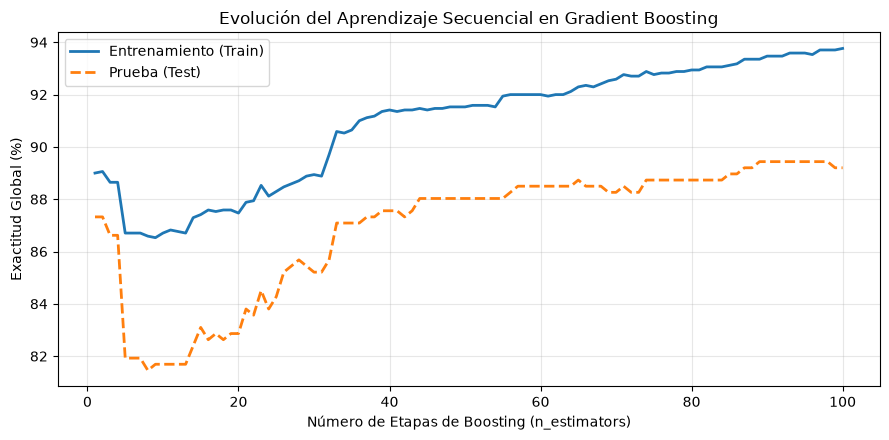

In [5]:
# Auditoría de convergencia por etapa usando staged_predict

# Obtenemos las predicciones paso a paso de cada etapa
train_stages = gb_model.staged_predict(X_train)
test_stages = gb_model.staged_predict(X_test)

# Calculamos la exactitud paso a paso para los datos Train & Test
train_acc_curve = [accuracy(y_train, p) * 100 for p in train_stages]
test_acc_curve = [accuracy(y_test, p) * 100 for p in test_stages]


# Gráfica de evolución
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, n_estimators + 1), train_acc_curve, label='Entrenamiento (Train)', linewidth=2)
plt.plot(range(1, n_estimators + 1), test_acc_curve, label='Prueba (Test)', linewidth=2, linestyle='--')
plt.xlabel('Número de Etapas de Boosting (n_estimators)')
plt.ylabel('Exactitud Global (%)')
plt.title('Evolución del Aprendizaje Secuencial en Gradient Boosting')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Análisis y Conclusiones Finales del Modelo (Gradient Boosting Balanceado vs. Random Forest)

El desarrollo de nuestro clasificador **Gradient Boosting Multiclase** nos permitió comprobar el impacto directo de nuestra estrategia de balanceo de clases frente al severo desbalance del dataset (77.85% Normal vs. 8.28% Patológico). En una primera fase experimental evaluando el algoritmo con los datos crudos (*sin balancear* o con balanced=False), el modelo obtenía una Exactitud Global aparentemente alta (93.43%), pero demostró ser un sistema ineficiente para la clínica: al no penalizar los errores en clases minoritarias, su *Recall* en fetos Patológicos se quedaba estancado en un bajo **73.08%**, dejando escapar a varios bebés en riesgo[cite: 7]. 

Para solucionar esto, integramos nuestro balanceo por pesos (balanced=True) en la clase personalizada. Al revisar la nueva gráfica de evolución por etapas (staged_predict), el cambio fue evidente: el estancamiento inicial desapareció, permitiendo que la exactitud se estabilizara de forma progresiva hasta alcanzar un **89.20% en el conjunto de prueba**, demostrando un aprendizaje sólido y sin sobreajuste con árboles de profundidad 3 y learning_rate=0.1.

Ya en la evaluación detallada con los datos de prueba, el balanceo nos mostro el efecto clínico deseado: **sacrificamos exactitud general para ganar sensibilidad en las emergencias**. Las métricas por clase muestran un gran cambio:

* **Clase 3 (Patológico):** El *Recall* subió drásticamente de 73.08% a **84.62%**, acompañado de una Precisión del **88.00%** y un F1-Score de 86.27%. En la matriz de confusión, de los 26 casos patológicos reales, el modelo ahora detecta 22 de manera directa, manda 2 a revisión como sospechosos y reduce los falsos negativos críticos a solo 2.

* **Clase 2 (Sospechoso):** Alcanzó un *Recall* de **89.23%**, asegurando que  casi  ningún caso clase 2 pase desapercibido, situando el Promedio Macro F1-Score global en **84.33%**.

* **Clase 1 (Normal):** Obtuvo una Precisión sobresaliente del **97.40%**, garantizando que cuando el modelo dictamina que un feto está sano, la certeza es sumamente alta.

En conclusión, esta comparativa nos deja claro cómo elegir una herramienta según las prioridades médicas. Para un primer filtro de emergencia donde lo vital es no dejar ir a ningún feto con riesgo de hipoxia, nuestro **Random Forest con Bootstrap balanceado** (84.62% de Recall) y este nuevo **Gradient Boosting Balanceado** (84.62% de Recall) son bastante similares. Sin embargo, el **Gradient Boosting Balanceado** destaca además por su excelente capacidad para captar casos sospechosos y ofrecer una gran certeza al descartar falsas alarmas en pacientes normales.


> **Nota técnica para el evaluador / lector:** *Si deseas replicar la fase experimental previa y comprobar el comportamiento del algoritmo sin ponderación de clases, puedes re-ejecutar este notebook cambiando el parámetro de inicialización a balanced=False.*